# CityRide 共享单车运营指挥中心：探索性数据分析（EDA）

本分析面向共享单车运营经理，使用逐小时骑行数据识别需求高峰，以及工作日/周末、季节和天气对骑行量的影响，为车辆调度与维护资源安排提供依据。

## 1. 项目背景和业务问题

CityRide 需要在合适的时间、天气和季节条件下配置车辆调度与维护能力。本 EDA 回答以下问题：何时需求最高？工作日与周末/节假日的小时需求模式是否不同？天气、季节和用户类型与总骑行量有何关系？

## 2. 导入库并读取数据

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use('default')
DATA_PATH = Path('hour.csv')
if not DATA_PATH.exists():
    DATA_PATH = Path('class-streamlit/hour.csv')

df = pd.read_csv(DATA_PATH)
print(f'Loaded {DATA_PATH}: {df.shape[0]:,} rows and {df.shape[1]} columns.')

Loaded hour.csv: 17,379 rows and 17 columns.


## 3. 数据概览与质量检查

先检查数据规模、样例、字段类型、缺失值和数值字段的分布。

In [2]:
print('Data shape:', df.shape)
display(df.head())
print('\nColumn names:')
print(df.columns.tolist())
print('\nData types:')
display(df.dtypes.to_frame('dtype'))
print('\nMissing values per column:')
display(df.isna().sum().to_frame('missing_values'))
print('\nDescriptive statistics:')
display(df.describe().T)

Data shape: (17379, 17)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1



Column names:
['instant', 'dteday', 'season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']

Data types:


,dtype
instant,int64
dteday,str
season,int64
yr,int64
mnth,int64
hr,int64
holiday,int64
weekday,int64
workingday,int64
weathersit,int64



Missing values per column:


,missing_values
instant,0
dteday,0
season,0
yr,0
mnth,0
hr,0
holiday,0
weekday,0
workingday,0
weathersit,0



Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
instant,17379.0,8690.000000,5017.029500,1.00,4345.5000,8690.0000,13034.5000,17379.0000
season,17379.0,2.501640,1.106918,1.00,2.0000,3.0000,3.0000,4.0000
yr,17379.0,0.502561,0.500008,0.00,0.0000,1.0000,1.0000,1.0000
mnth,17379.0,6.537775,3.438776,1.00,4.0000,7.0000,10.0000,12.0000
hr,17379.0,11.546752,6.914405,0.00,6.0000,12.0000,18.0000,23.0000
holiday,17379.0,0.028770,0.167165,0.00,0.0000,0.0000,0.0000,1.0000
weekday,17379.0,3.003683,2.005771,0.00,1.0000,3.0000,5.0000,6.0000
workingday,17379.0,0.682721,0.465431,0.00,0.0000,1.0000,1.0000,1.0000
weathersit,17379.0,1.425283,0.639357,1.00,1.0000,1.0000,2.0000,4.0000
temp,17379.0,0.496987,0.192556,0.02,0.3400,0.5000,0.6600,1.0000


**结论：** 数据包含逐小时记录。运行上方单元可确认行列数、各字段类型和缺失值；后续分析直接以 `cnt` 为需求指标。

## 4. 关键字段说明

- `hr`：小时，范围 0–23。
- `cnt`：总骑行量，等于 `casual` 与 `registered` 的合计。
- `casual`：非注册用户骑行量。
- `registered`：注册用户骑行量。
- `workingday`：是否工作日（1=工作日，0=周末或节假日）。
- `weathersit`：天气等级（1=晴朗/少云，2=薄雾/多云，3=小雨小雪，4=强降雨/降雪）。
- `season`：季节编码（1=Spring，2=Summer，3=Fall，4=Winter）。
- `temp`、`hum`、`windspeed`：归一化后的温度、湿度和风速。

## 5. 创建易读标签列

In [3]:
season_map = {1: 'Spring', 2: 'Summer', 3: 'Fall', 4: 'Winter'}
weather_map = {1: 'Clear', 2: 'Mist/Cloudy', 3: 'Light Rain/Snow', 4: 'Heavy Rain/Snow'}

df['season_label'] = df['season'].map(season_map)
df['weather_label'] = df['weathersit'].map(weather_map)
df['day_type'] = df['workingday'].map({1: 'Working day', 0: 'Weekend/Holiday'})

display(df[['season', 'season_label', 'weathersit', 'weather_label', 'workingday', 'day_type']].head())

,season,season_label,weathersit,weather_label,workingday,day_type
0,1,Spring,1,Clear,0,Weekend/Holiday
1,1,Spring,1,Clear,0,Weekend/Holiday
2,1,Spring,1,Clear,0,Weekend/Holiday
3,1,Spring,1,Clear,0,Weekend/Holiday
4,1,Spring,1,Clear,0,Weekend/Holiday


**结论：** 标签列将编码变量转成面向运营人员的可读类别，便于图表标题、图例和仪表板筛选。

## 6. 小时、日期类型、天气、季节与用户结构分析

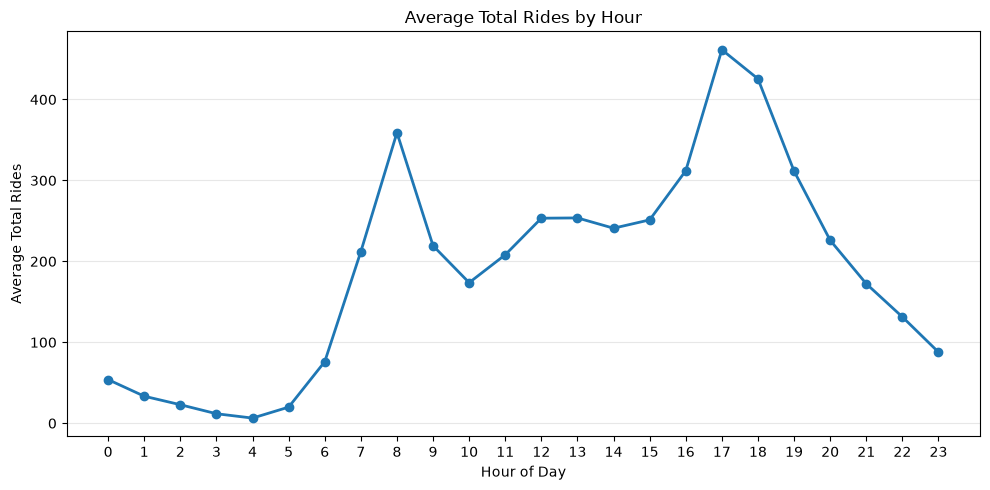

Overall peak: 17:00, with 461.5 average rides.


In [4]:
hourly_avg = df.groupby('hr', as_index=False)['cnt'].mean()
plt.figure(figsize=(10, 5))
plt.plot(hourly_avg['hr'], hourly_avg['cnt'], marker='o', color='#1f77b4', linewidth=2)
plt.title('Average Total Rides by Hour')
plt.xlabel('Hour of Day')
plt.ylabel('Average Total Rides')
plt.xticks(range(24))
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

peak_hour = hourly_avg.loc[hourly_avg['cnt'].idxmax()]
print(f"Overall peak: {int(peak_hour['hr'])}:00, with {peak_hour['cnt']:.1f} average rides.")

**结论：** 全部记录的平均骑行量在 17:00 最高（约 461.5 次），应作为晚高峰调度和车辆回补的重点时段。

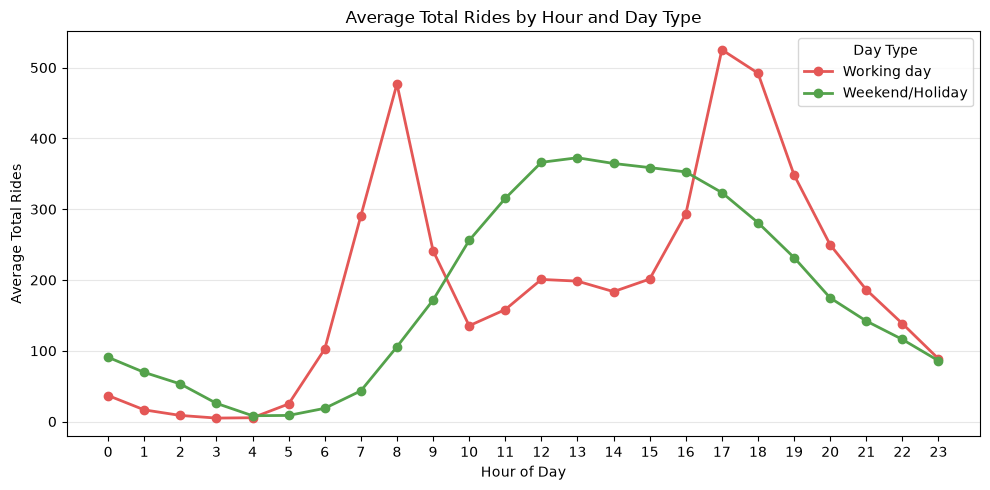

Working day peak: 17:00 (525.3 average rides)
Weekend/Holiday peak: 13:00 (372.7 average rides)


In [5]:
hourly_daytype = df.groupby(['hr', 'day_type'], as_index=False)['cnt'].mean()
plt.figure(figsize=(10, 5))
for label, color in [('Working day', '#e45756'), ('Weekend/Holiday', '#54a24b')]:
    subset = hourly_daytype[hourly_daytype['day_type'] == label]
    plt.plot(subset['hr'], subset['cnt'], marker='o', label=label, color=color, linewidth=2)
plt.title('Average Total Rides by Hour and Day Type')
plt.xlabel('Hour of Day')
plt.ylabel('Average Total Rides')
plt.xticks(range(24))
plt.legend(title='Day Type')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

for label in ['Working day', 'Weekend/Holiday']:
    row = hourly_daytype[hourly_daytype['day_type'] == label].sort_values('cnt', ascending=False).iloc[0]
    print(f"{label} peak: {int(row['hr'])}:00 ({row['cnt']:.1f} average rides)")

**结论：** 工作日峰值在 17:00（约 525.3 次），周末/节假日峰值在 13:00（约 372.7 次）。运营排班应按日期类型区分，而非使用单一日内曲线。

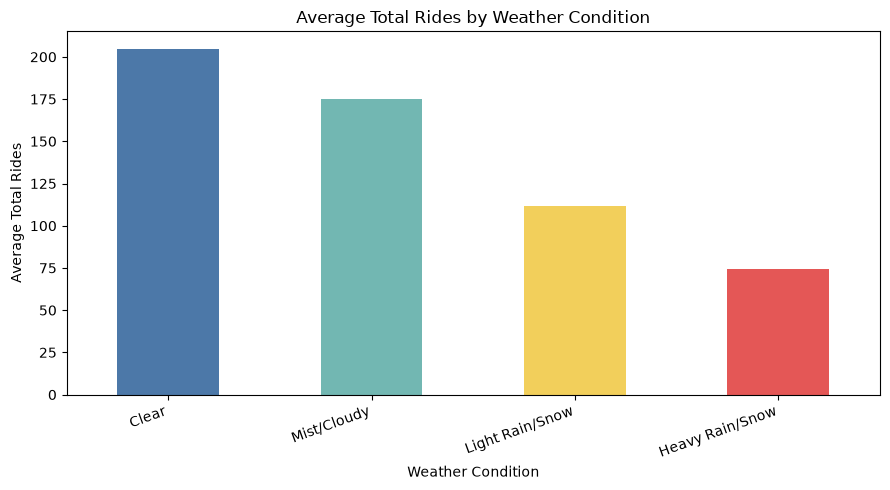

,average_rides
weather_label,
Clear,204.869272
Mist/Cloudy,175.165493
Light Rain/Snow,111.579281
Heavy Rain/Snow,74.333333


In [6]:
weather_order = ['Clear', 'Mist/Cloudy', 'Light Rain/Snow', 'Heavy Rain/Snow']
weather_avg = df.groupby('weather_label')['cnt'].mean().reindex(weather_order).dropna()
plt.figure(figsize=(9, 5))
weather_avg.plot(kind='bar', color=['#4c78a8', '#72b7b2', '#f2cf5b', '#e45756'])
plt.title('Average Total Rides by Weather Condition')
plt.xlabel('Weather Condition')
plt.ylabel('Average Total Rides')
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.show()
display(weather_avg.to_frame('average_rides'))

**结论：** 晴朗天气的平均骑行量最高（约 204.9 次）；天气恶化后需求下降。强降雨/降雪样本较少，解读该类别时应同时查看样本量。

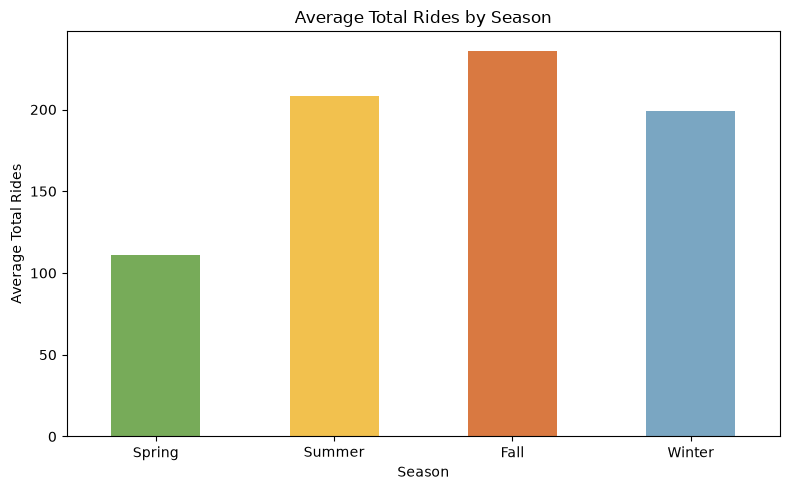

,average_rides
season_label,
Spring,111.114569
Summer,208.344069
Fall,236.016237
Winter,198.868856


In [7]:
season_order = ['Spring', 'Summer', 'Fall', 'Winter']
season_avg = df.groupby('season_label')['cnt'].mean().reindex(season_order)
plt.figure(figsize=(8, 5))
season_avg.plot(kind='bar', color=['#77ab59', '#f2c14e', '#d97941', '#7aa6c2'])
plt.title('Average Total Rides by Season')
plt.xlabel('Season')
plt.ylabel('Average Total Rides')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
display(season_avg.to_frame('average_rides'))

**结论：** Fall 的平均骑行量最高（约 236.0 次），Spring 最低（约 111.1 次）。季节性应纳入车辆与维护能力规划。

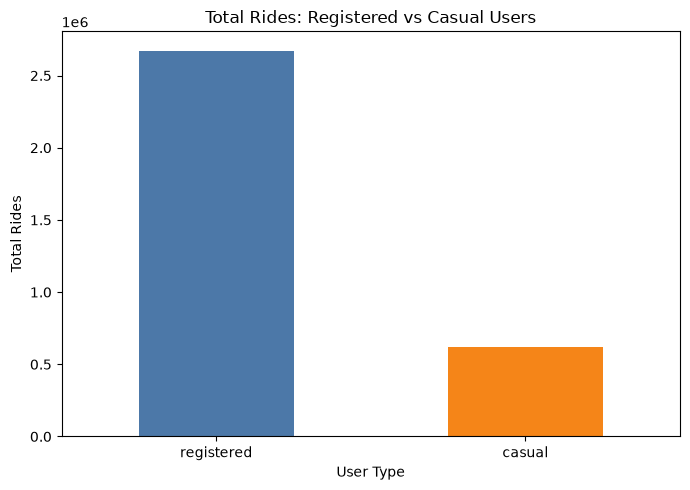

,total_rides
registered,2672662
casual,620017


Registered users account for 81.2% of all rides.


In [8]:
user_totals = df[['registered', 'casual']].sum().sort_values(ascending=False)
plt.figure(figsize=(7, 5))
user_totals.plot(kind='bar', color=['#4c78a8', '#f58518'])
plt.title('Total Rides: Registered vs Casual Users')
plt.xlabel('User Type')
plt.ylabel('Total Rides')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
display(user_totals.to_frame('total_rides'))
print(f"Registered users account for {user_totals['registered'] / df['cnt'].sum():.1%} of all rides.")

**结论：** 注册用户累计 2,672,662 次骑行（约占总量 81.2%），显著高于非注册用户的 620,017 次。保障通勤型注册用户需求应是运营优先事项。

## 7. Dashboard Design Recommendations

### 顶部 KPI
1. **总骑行量：3,292,679**，概览服务规模。
2. **平均每小时骑行量：189.5**，便于观察总体需求水平。
3. **高峰小时：17:00，平均 461.5 次骑行**，直接支持调度资源配置。

### 最值得保留的图表
1. **按工作日/周末（含节假日）分组的小时平均骑行量折线图**：直观看到工作日 17:00 与周末/节假日 13:00 的不同高峰。
2. **按天气条件的平均骑行量柱状图**：展示晴朗天气约 204.9 次、小雨/雪约 111.6 次的需求差异，有助于天气驱动的调度和维护预案。

### 推荐筛选器
季节、天气条件、工作日/周末/节假日、小时、年份（`yr`）和月份（`mnth`）。

### 不应放进大屏的内容
1. **原始记录表及全部 17 个字段**：信息密度过高，不支持快速调度决策，应放在明细页或下载区。
2. **`instant` 序号和原始数值编码（如 `season=3`）**：缺乏业务含义；应使用标签列，序号无需展示。

### 数据使用边界
- 数据仅覆盖 **2011–2012**，不能直接当作当前需求或预测结果。
- `weathersit` 是分级编码而非实时天气预报，`temp`、`hum`、`windspeed` 也是归一化数值，展示时应明确口径。
- 数据没有站点位置、可用车辆、停车桩容量、故障、行程起终点或实时库存，因此不能据此直接决定具体站点的调度路线。
- 这是观测性汇总数据，天气和季节的关联不等于因果关系。